# Lab 2 · The angular power spectrum of Planck maps
From a raw 70 GHz sky to the CMB acoustic peaks: mask → noise → beam → spectrum.
Theory, the meaning of each block and the plots are explained on the website (Lesson 11 and Lab 2 pages).

## 0 · Setup (Colab or local)

In [1]:
import os, sys
if "google.colab" in sys.modules:                 # Colab: install healpy, read data from Drive
    !pip -q install healpy
    from google.colab import drive
    drive.mount("/content/drive")
    DATA = "/content/drive/MyDrive/Lab 2/data"    # <- change to where your data/ folder is
else:
    DATA = "data"                                 # local: data/ next to this notebook
FIG = "figures"; os.makedirs(FIG, exist_ok=True)
print(sorted(os.listdir(DATA)))

['COM_PowerSpect_CMB-TT-full_R3.01.txt', 'COM_PowerSpect_CMB-base-plikHM-TTTEEE-lowl-lowE-lensing-minimum-theory_R3.01.txt', 'mask_UT78_n1024.fits', 'pixel_window_n1024.fits', 'planck_T070_n1024_uK.fits', 'planck_T100_n1024_uK.fits']


## 1 · Settings and imports

In [2]:
import numpy as np
import healpy as hp
import matplotlib.pyplot as plt

FREQ = 70                                   # 70 (core) or 100 (extension A)
CROSS = True                                # extension C: cross-spectrum 70 x 100
FWHM_ARCMIN = {70: 13.08, 100: 9.66}        # effective beam FWHM, Planck 2018 I, Table 4

def path(name):
    """Full path of a file in data/."""
    return os.path.join(DATA, name)

## 2 · Step 0 — read the map and the mask, and look at them

Step 0: 70 GHz map, Nside = 1024, Npix = 12582912, pixel side = 3.44 arcmin
        unobserved pixels: 0


        mean = 86.5 muK, rms = 435.7 muK, max = 1.5e+05 muK
        f_sky = 0.7780


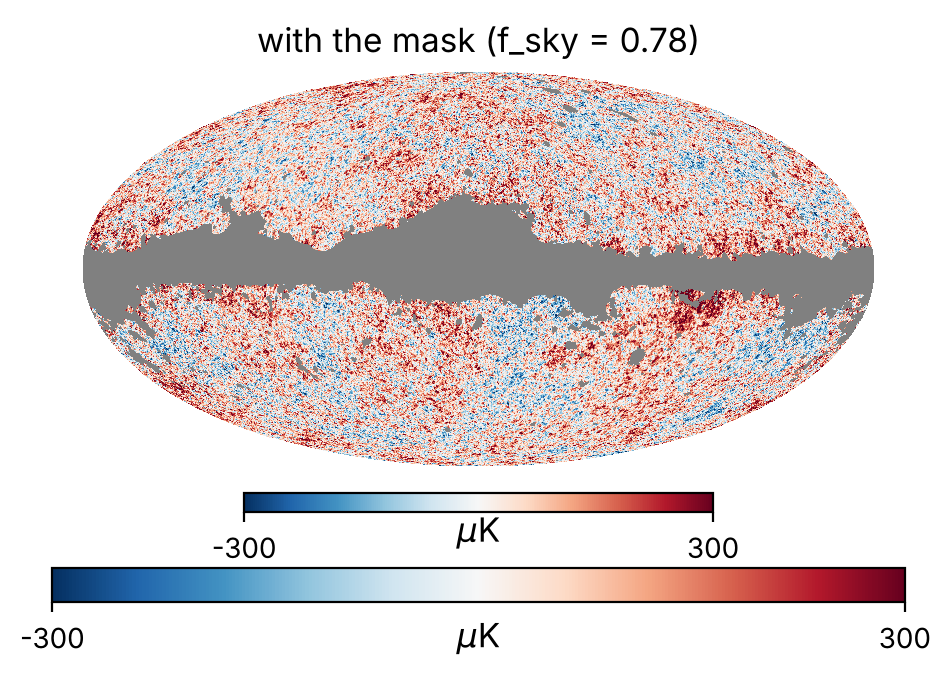

In [3]:
m = hp.read_map(path(f"planck_T{FREQ:03d}_n1024_uK.fits")).astype(np.float64)
mask = hp.read_map(path("mask_UT78_n1024.fits")).astype(np.float64)

nside = hp.npix2nside(m.size)               # Npix = 12 Nside^2  ->  Nside
print(f"Step 0: {FREQ} GHz map, Nside = {nside}, Npix = {m.size}, "
      f"pixel side = {hp.nside2resol(nside, arcmin=True):.2f} arcmin")

bad = m < -1e30                             # UNSEEN pixels (test with < -1e30, not ==)
print(f"        unobserved pixels: {bad.sum()}")
if bad.any():
    mask[bad] = 0.0
    m[bad] = 0.0

good = ~bad
print(f"        mean = {m[good].mean():.1f} muK, rms = {m[good].std():.1f} muK, "
      f"max = {m[good].max():.3g} muK")
fsky = mask.mean()
print(f"        f_sky = {fsky:.4f}")

plt.figure(figsize=(11, 3.6))
hp.mollview(m, sub=(1, 2, 1), min=-300, max=300, unit=r"$\mu$K", cmap="RdBu_r",
            title=f"Planck {FREQ} GHz", hold=True)
masked = m.copy()
masked[mask == 0] = hp.UNSEEN
hp.mollview(masked, sub=(1, 2, 2), min=-300, max=300, unit=r"$\mu$K", cmap="RdBu_r",
            title=f"with the mask (f_sky = {fsky:.2f})", hold=True)
plt.savefig(f"{FIG}/step0_maps_{FREQ}.png", dpi=120, bbox_inches="tight")
plt.show()

## 3 · Step 1 — the power spectrum of the whole sky

In [4]:
lmax = 3 * nside - 1
ell = np.arange(lmax + 1)

def Dl(cl):
    """D_l = l(l+1) C_l / 2 pi  [muK^2]"""
    return ell * (ell + 1) * cl / (2 * np.pi)

print("Step 1: anafast on the full sky ...")
cl_full = hp.anafast(m, lmax=lmax)

th = np.loadtxt(path("COM_PowerSpect_CMB-base-plikHM-TTTEEE-lowl-lowE-lensing-"
                     "minimum-theory_R3.01.txt"))
Dth = np.zeros(lmax + 1)
Dth[2:2 + len(th)] = th[:, 1]               # model D_l on our l grid (0 beyond 2508)
has_model = Dth > 0

for L in (10, 220, 800, 2000):
    print(f"        l = {L:4d}: D_l(full sky) = {Dl(cl_full)[L]:9.4g} muK^2, "
          f"model = {Dth[L]:7.4g} muK^2")

Step 1: anafast on the full sky ...


        l =   10: D_l(full sky) = 2.252e+04 muK^2, model =   817.2 muK^2
        l =  220: D_l(full sky) =  5.16e+04 muK^2, model =    5730 muK^2
        l =  800: D_l(full sky) = 3.262e+04 muK^2, model =    2526 muK^2
        l = 2000: D_l(full sky) =      2064 muK^2, model =   231.3 muK^2


## 4 · Step 2 — cut the Galaxy with the mask

In [5]:
mm = m.copy()
mm[mask == 0] = hp.UNSEEN                   # fit only on the kept sky
mono, dip = hp.fit_dipole(mm)
print(f"Step 2: on the kept sky: monopole = {mono:.1f} muK, |dipole| = {np.linalg.norm(dip):.1f} muK")
mm = hp.remove_dipole(mm)                   # removes monopole and dipole

mm[mask == 0] = 0.0
print("        anafast on the masked sky ...")
cl_mask = hp.anafast(mm, lmax=lmax)
cl_mask /= fsky                             # pseudo-C_l, corrected on average

for L in (2, 10, 220, 800, 2000):
    print(f"        l = {L:4d}: D_l(masked) = {Dl(cl_mask)[L]:9.4g} muK^2, model = {Dth[L]:7.4g}")

Step 2: on the kept sky: monopole = 35.9 muK, |dipole| = 4.7 muK


        anafast on the masked sky ...


        l =    2: D_l(masked) =     149.9 muK^2, model =    1017
        l =   10: D_l(masked) =     731.9 muK^2, model =   817.2
        l =  220: D_l(masked) =      5166 muK^2, model =    5730
        l =  800: D_l(masked) =     852.8 muK^2, model =    2526
        l = 2000: D_l(masked) =      2065 muK^2, model =   231.3


## 5 · Step 3 — the noise bias

In [6]:
hi = (ell >= 2000) & (ell <= 2500) if FREQ == 70 else (ell >= 2600) & (ell <= 3000)
N = cl_mask[hi].mean()
print(f"Step 3: white noise level N = {N:.4g} muK^2 sr (mean of C_l for l = "
      f"{ell[hi][0]}-{ell[hi][-1]})")

for a, b in [(1200, 1500), (1500, 2000), (2000, 2500), (2500, 3000)]:
    print(f"        l = {a}-{b}: mean C_l / N = {cl_mask[a:b].mean() / N:.3f}")

Step 3: white noise level N = 0.003267 muK^2 sr (mean of C_l for l = 2000-2500)
        l = 1200-1500: mean C_l / N = 1.059
        l = 1500-2000: mean C_l / N = 1.027
        l = 2000-2500: mean C_l / N = 1.000
        l = 2500-3000: mean C_l / N = 0.946


## 6 · Step 4 — the beam and the pixels

In [7]:
B = hp.gauss_beam(np.radians(FWHM_ARCMIN[FREQ] / 60.0), lmax=lmax)
W = np.atleast_2d(hp.read_cl(path("pixel_window_n1024.fits")))[0][:lmax + 1]
BW2 = (B * W) ** 2

for q in (0.5, 0.1, 0.01):
    print(f"Step 4: B_l^2 = {q} at l = {np.argmax(B ** 2 < q)}")

model_seen = Dth * BW2 + Dl(np.full(lmax + 1, N))

cl_cmb = (cl_mask - N) / BW2                # deconvolution
D_cmb = Dl(cl_cmb)

dl = 30
edges = np.arange(2, lmax + 1, dl)
lc = 0.5 * (edges[:-1] + edges[1:] - 1)
Db = np.array([D_cmb[a:b].mean() for a, b in zip(edges[:-1], edges[1:])])
Dthb = np.array([Dth[a:b].mean() for a, b in zip(edges[:-1], edges[1:])])
DNb = np.array([Dl(np.full(lmax + 1, N) / BW2)[a:b].mean() for a, b in zip(edges[:-1], edges[1:])])
err = np.sqrt(2.0 / ((2 * lc + 1) * fsky * dl)) * (Dthb + DNb)

for a, b in [(30, 300), (300, 600), (600, 800), (800, 1000), (1000, 1200)]:
    k = (lc >= a) & (lc < b)
    print(f"        l = {a}-{b}: recovered / model = {np.mean(Db[k] / Dthb[k]):.3f}")

Step 4: B_l^2 = 0.5 at l = 515
Step 4: B_l^2 = 0.1 at l = 939
Step 4: B_l^2 = 0.01 at l = 1328
        l = 30-300: recovered / model = 0.991
        l = 300-600: recovered / model = 1.050
        l = 600-800: recovered / model = 1.149
        l = 800-1000: recovered / model = 1.419
        l = 1000-1200: recovered / model = 2.431


## 7 · Extension B — what is left after the correction?

In [8]:
Cth = np.zeros(lmax + 1)
Cth[2:] = 2 * np.pi * Dth[2:] / (ell[2:] * (ell[2:] + 1))
s = slice(30, 1200)
y = cl_mask[s] - N - Cth[s] * BW2[s]        # excess, as the instrument sees it
x = BW2[s]                                  # shape of a white sky after the beam
var = 2 * (Cth[s] * BW2[s] + N) ** 2 / ((2 * ell[s] + 1) * fsky)
A = (x * y / var).sum() / (x * x / var).sum()
chi_A = ((y - A * x) ** 2 / var).sum()
chi_0 = (y ** 2 / var).sum()
print(f"Ext. B: A = {A:.3g} muK^2 sr; chi^2 = {chi_0:.0f} without A, {chi_A:.0f} with A "
      f"({s.stop - s.start} multipoles)")

best = (np.inf, None)
for fw in np.arange(0.85, 1.0001, 0.0025) * FWHM_ARCMIN[FREQ]:
    x2 = (hp.gauss_beam(np.radians(fw / 60), lmax=lmax) * W)[s] ** 2
    c2 = ((cl_mask[s] - N - Cth[s] * x2) ** 2 / var).sum()
    best = min(best, (c2, fw))
print(f"        alternative, no A and a free beam width: best chi^2 = {best[0]:.0f} "
      f"at FWHM = {best[1]:.2f} arcmin")

Ext. B: A = 0.00477 muK^2 sr; chi^2 = 5722 without A, 1532 with A (1170 multipoles)
        alternative, no A and a free beam width: best chi^2 = 2162 at FWHM = 12.23 arcmin


## 8 · Figures of steps 1–4

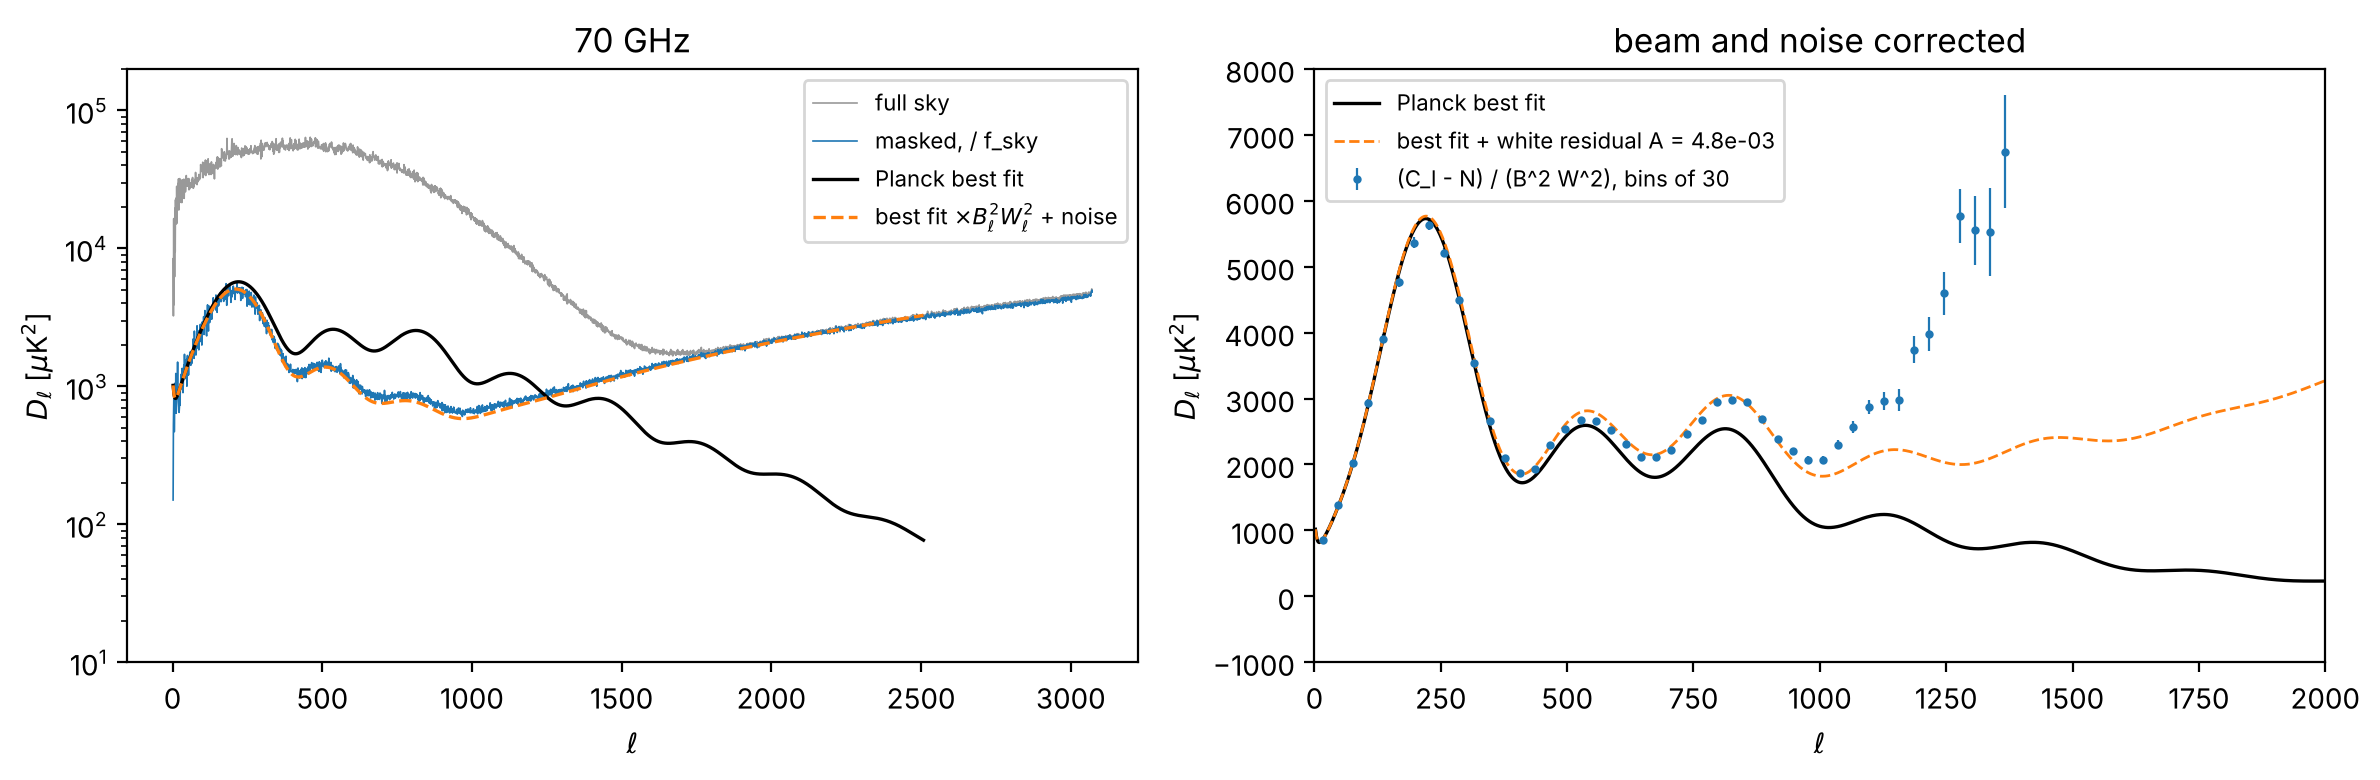

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].semilogy(ell[2:], Dl(cl_full)[2:], color="0.6", lw=0.6, label="full sky")
ax[0].semilogy(ell[2:], Dl(cl_mask)[2:], lw=0.6, label="masked, / f_sky")
ax[0].semilogy(ell[has_model], Dth[has_model], "k", lw=1.2, label="Planck best fit")
ax[0].semilogy(ell[has_model], model_seen[has_model], "--", lw=1.2,
               label=r"best fit $\times B_\ell^2W_\ell^2$ + noise")
ax[0].set_xlabel(r"$\ell$"); ax[0].set_ylabel(r"$D_\ell$ [$\mu$K$^2$]")
ax[0].set_ylim(10, 2e5); ax[0].legend(fontsize=8); ax[0].set_title(f"{FREQ} GHz")

ax[1].errorbar(lc, Db, yerr=err, fmt="o", ms=2, lw=0.8, label="(C_l - N) / (B^2 W^2), bins of 30")
ax[1].plot(ell[has_model], Dth[has_model], "k", lw=1.2, label="Planck best fit")
ax[1].plot(ell[has_model], (Dth + Dl(np.full(lmax + 1, A)))[has_model], "--", lw=1.0,
           label=f"best fit + white residual A = {A:.1e}")
ax[1].set_xlim(0, 2000); ax[1].set_ylim(-1000, 8000)
ax[1].set_xlabel(r"$\ell$"); ax[1].set_ylabel(r"$D_\ell$ [$\mu$K$^2$]")
ax[1].legend(fontsize=8); ax[1].set_title("beam and noise corrected")
plt.tight_layout()
plt.savefig(f"{FIG}/steps1-4_spectra_{FREQ}.png", dpi=120)
plt.show()

## 9 · Extension C — the cross-spectrum 70 × 100

Ext. C: anafast of the cross-spectrum 70 x 100 ...


        l ~ 106: cross / model = 1.015
        l ~ 226: cross / model = 0.998
        l ~ 526: cross / model = 1.043
        l ~ 796: cross / model = 1.131
        l ~ 1006: cross / model = 1.588


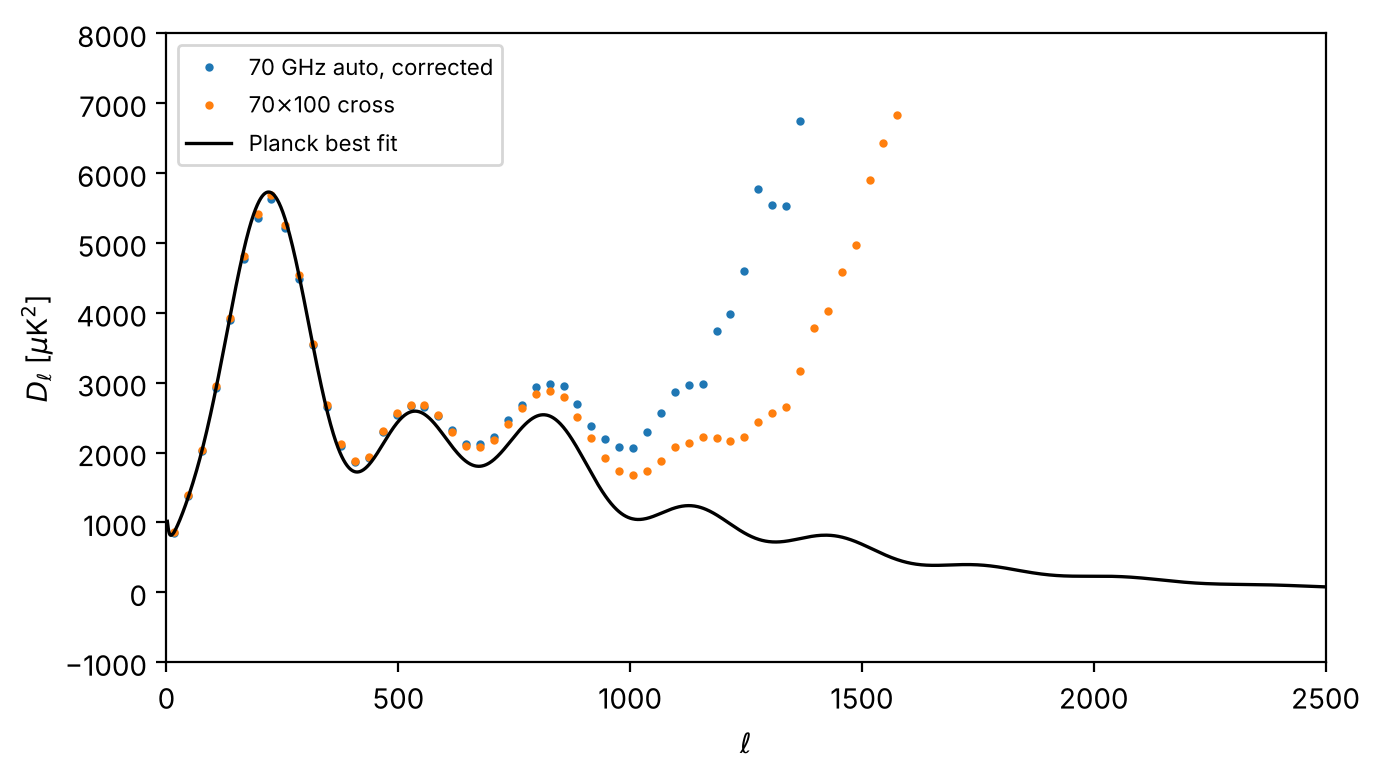

In [10]:
if CROSS:
    def masked_map(freq, mask):
        """Read a map, remove monopole and dipole on the kept sky, zero the cut pixels."""
        mp = hp.read_map(path(f"planck_T{freq:03d}_n1024_uK.fits")).astype(np.float64)
        mask = mask.copy()
        mask[mp < -1e30] = 0.0
        mp[mask == 0] = hp.UNSEEN
        mp = hp.remove_dipole(mp)
        mp[mask == 0] = 0.0
        return mp, mask

    mask0 = hp.read_map(path("mask_UT78_n1024.fits")).astype(np.float64)
    m70, mask_c = masked_map(70, mask0)
    m100, mask_c = masked_map(100, mask_c)  # common mask
    m70[mask_c == 0] = 0.0
    fsky_c = mask_c.mean()
    print("Ext. C: anafast of the cross-spectrum 70 x 100 ...")
    cl_x = hp.anafast(m70, map2=m100, lmax=lmax) / fsky_c
    B70 = hp.gauss_beam(np.radians(FWHM_ARCMIN[70] / 60), lmax=lmax)
    B100 = hp.gauss_beam(np.radians(FWHM_ARCMIN[100] / 60), lmax=lmax)
    D_x = Dl(cl_x / (B70 * B100 * W ** 2))  # no noise to subtract
    Dxb = np.array([D_x[a:b].mean() for a, b in zip(edges[:-1], edges[1:])])
    for L in (106, 226, 526, 796, 1006):
        k = np.argmin(abs(lc - L))
        print(f"        l ~ {lc[k]:.0f}: cross / model = {Dxb[k] / Dthb[k]:.3f}")

    plt.figure(figsize=(7, 4))
    plt.plot(lc, Db, "o", ms=2, label=f"{FREQ} GHz auto, corrected")
    plt.plot(lc, Dxb, "o", ms=2, label=r"70$\times$100 cross")
    plt.plot(ell[has_model], Dth[has_model], "k", lw=1.2, label="Planck best fit")
    plt.xlim(0, 2500); plt.ylim(-1000, 8000)
    plt.xlabel(r"$\ell$"); plt.ylabel(r"$D_\ell$ [$\mu$K$^2$]"); plt.legend(fontsize=8)
    plt.tight_layout()
    plt.savefig(f"{FIG}/extC_cross.png", dpi=120)
    plt.show()

## 10 · Extension A — the same analysis at 100 GHz
Set `FREQ = 100` in block 1 and run blocks 2–8 again (the noise band moves to ℓ = 2600–3000).
Block 11 does this automatically for both channels.

## 11 · NEW — both channels side by side: plots and results table

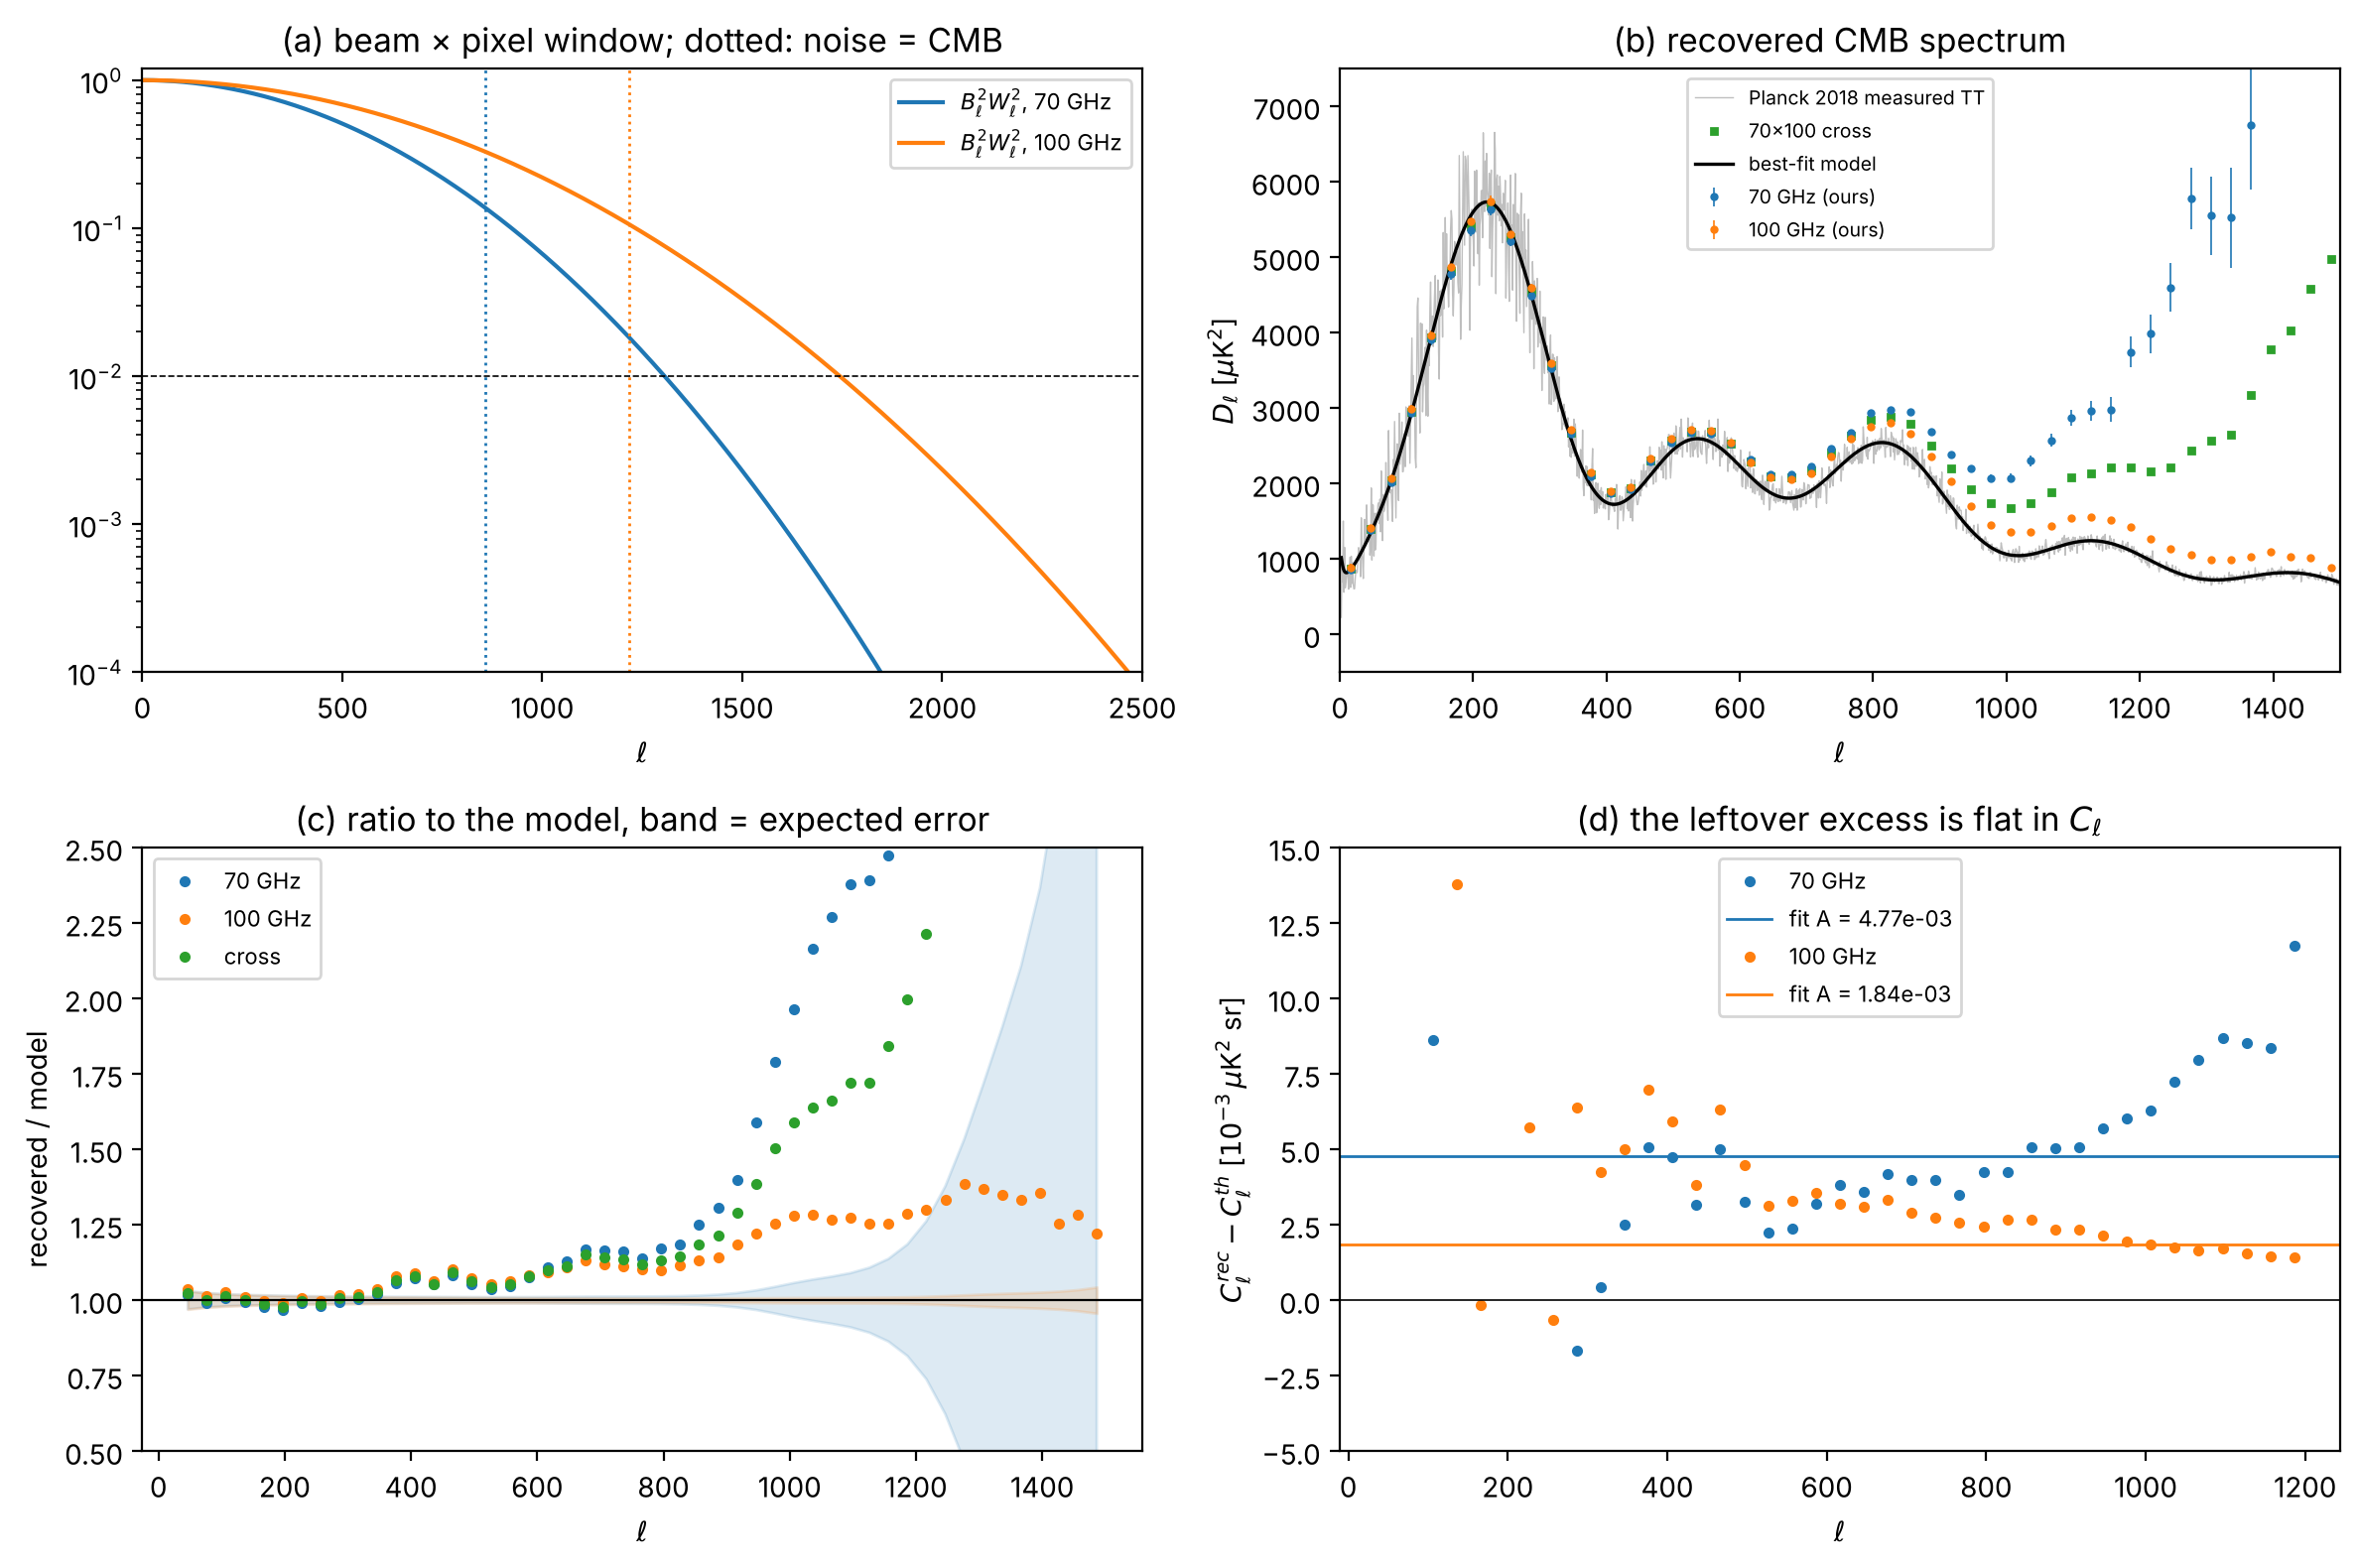

cross / model at l ~ 106, 226, 526, 796, 1006: [np.float64(1.02), np.float64(1.0), np.float64(1.04), np.float64(1.13), np.float64(1.59)]


,70 GHz,100 GHz
Unobserved pixels,0,1
Mean / rms [muK],86.5 / 436,108.4 / 497
f_sky,0.778,0.778
Monopole / |dipole| on kept sky [muK],35.9 / 4.7,32.9 / 3.7
Noise N [muK^2 sr],3.27e-03,5.14e-04
l where B^2 = 0.5 / 0.01,515 / 1328,698 / 1798
l where noise/B^2 > CMB,856,1216
recovered/model l = 30-300,0.99,1.01
recovered/model l = 300-600,1.05,1.07
recovered/model l = 600-800,1.15,1.11


In [11]:
import pandas as pd

def pipeline(freq):
    """Steps 0-4 and extension B for one channel, condensed. Returns a dict of results."""
    mp = hp.read_map(path(f"planck_T{freq:03d}_n1024_uK.fits")).astype(np.float64)
    mk = hp.read_map(path("mask_UT78_n1024.fits")).astype(np.float64)
    bad = mp < -1e30; mk[bad] = 0.0; mp[bad] = 0.0
    r = dict(freq=freq, unseen=int(bad.sum()), mean=mp[~bad].mean(), rms=mp[~bad].std(),
             vmax=mp[~bad].max(), fsky=mk.mean())
    q = mp.copy(); q[mk == 0] = hp.UNSEEN
    mono, dip = hp.fit_dipole(q); r.update(mono=mono, dip=np.linalg.norm(dip))
    q = hp.remove_dipole(q); q[mk == 0] = 0.0
    c = hp.anafast(q, lmax=lmax) / r["fsky"]
    band = (ell >= 2000) & (ell <= 2500) if freq == 70 else (ell >= 2600) & (ell <= 3000)
    n = c[band].mean()
    b = hp.gauss_beam(np.radians(FWHM_ARCMIN[freq] / 60), lmax=lmax)
    bw2 = (b * W) ** 2
    d = Dl((c - n) / bw2)
    db = np.array([d[a:e].mean() for a, e in zip(edges[:-1], edges[1:])])
    dnb = np.array([Dl(np.full(lmax + 1, n) / bw2)[a:e].mean() for a, e in zip(edges[:-1], edges[1:])])
    er = np.sqrt(2.0 / ((2 * lc + 1) * r["fsky"] * dl)) * (Dthb + dnb)
    yy = c[s] - n - Cth[s] * bw2[s]; xx = bw2[s]
    vv = 2 * (Cth[s] * bw2[s] + n) ** 2 / ((2 * ell[s] + 1) * r["fsky"])
    a_ = (xx * yy / vv).sum() / (xx * xx / vv).sum()
    r.update(N=n, cl=c, B2=b ** 2, BW2=bw2, Db=db, err=er, DNb=dnb, A=a_,
             chi0=(yy ** 2 / vv).sum(), chiA=((yy - a_ * xx) ** 2 / vv).sum(),
             l05=int(np.argmax(b ** 2 < 0.5)), l001=int(np.argmax(b ** 2 < 0.01)),
             reach=float(lc[np.argmax((dnb > Dthb) & (lc > 200))]))   # noise/B^2 > CMB
    for a, e in [(30, 300), (300, 600), (600, 800), (800, 1000)]:
        k = (lc >= a) & (lc < e); r[f"ratio {a}-{e}"] = np.mean(db[k] / Dthb[k])
    return r

R = {f: pipeline(f) for f in (70, 100)}

# Planck's own measured spectrum (TT full), for comparison with our points
pl = np.loadtxt(path("COM_PowerSpect_CMB-TT-full_R3.01.txt"))

fig, ax = plt.subplots(2, 2, figsize=(12, 8))
# (a) the transfer functions: how much sky each channel lets through
for f, col in ((70, "C0"), (100, "C1")):
    ax[0, 0].semilogy(ell[2:], R[f]["BW2"][2:], col, label=f"$B_\\ell^2W_\\ell^2$, {f} GHz")
    ax[0, 0].axvline(R[f]["reach"], color=col, ls=":", lw=1)
ax[0, 0].axhline(0.01, color="k", lw=0.6, ls="--")
ax[0, 0].set_ylim(1e-4, 1.2); ax[0, 0].set_xlim(0, 2500)
ax[0, 0].set_xlabel(r"$\ell$"); ax[0, 0].set_title("(a) beam × pixel window; dotted: noise = CMB")
ax[0, 0].legend(fontsize=8)
# (b) recovered spectra vs Planck model and Planck measurement
ax[0, 1].plot(pl[:, 0], pl[:, 1], color="0.75", lw=0.5, label="Planck 2018 measured TT")
for f, col in ((70, "C0"), (100, "C1")):
    ax[0, 1].errorbar(lc, R[f]["Db"], yerr=R[f]["err"], fmt="o", ms=2, lw=0.6, color=col, label=f"{f} GHz (ours)")
if CROSS: ax[0, 1].plot(lc, Dxb, "s", ms=2, color="C2", label="70×100 cross")
ax[0, 1].plot(ell[has_model], Dth[has_model], "k", lw=1.2, label="best-fit model")
ax[0, 1].set_xlim(0, 1500); ax[0, 1].set_ylim(-500, 7500)
ax[0, 1].set_xlabel(r"$\ell$"); ax[0, 1].set_ylabel(r"$D_\ell$ [$\mu$K$^2$]")
ax[0, 1].set_title("(b) recovered CMB spectrum"); ax[0, 1].legend(fontsize=7)
# (c) ratio to the model with the expected error
for f, col in ((70, "C0"), (100, "C1")):
    k = (lc > 20) & (lc < 1500)
    ax[1, 0].plot(lc[k], R[f]["Db"][k] / Dthb[k], ".", color=col, label=f"{f} GHz")
    ax[1, 0].fill_between(lc[k], 1 - R[f]["err"][k] / Dthb[k], 1 + R[f]["err"][k] / Dthb[k], color=col, alpha=0.15)
if CROSS: ax[1, 0].plot(lc[k], Dxb[k] / Dthb[k], ".", color="C2", label="cross")
ax[1, 0].axhline(1, color="k", lw=0.8); ax[1, 0].set_ylim(0.5, 2.5)
ax[1, 0].set_xlabel(r"$\ell$"); ax[1, 0].set_ylabel("recovered / model")
ax[1, 0].set_title("(c) ratio to the model, band = expected error"); ax[1, 0].legend(fontsize=8)
# (d) the excess in C_l: flat = white sky component (unresolved sources)
for f, col in ((70, "C0"), (100, "C1")):
    exc = (R[f]["cl"] - R[f]["N"]) / R[f]["BW2"] - Cth
    exb = np.array([exc[a:e].mean() for a, e in zip(edges[:-1], edges[1:])])
    k = (lc > 30) & (lc < 1200)
    ax[1, 1].plot(lc[k], exb[k] * 1e3, ".", color=col, label=f"{f} GHz")
    ax[1, 1].axhline(R[f]["A"] * 1e3, color=col, lw=1, label=f"fit A = {R[f]['A']:.2e}")
ax[1, 1].axhline(0, color="k", lw=0.6); ax[1, 1].set_ylim(-5, 15)
ax[1, 1].set_xlabel(r"$\ell$"); ax[1, 1].set_ylabel(r"$C_\ell^{rec}-C_\ell^{th}$ [$10^{-3}\,\mu$K$^2$ sr]")
ax[1, 1].set_title("(d) the leftover excess is flat in $C_\\ell$"); ax[1, 1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{FIG}/new_summary.png", dpi=120); plt.show()

# results table
rows = {
    "Unobserved pixels": [R[f]["unseen"] for f in (70, 100)],
    "Mean / rms [muK]": [f"{R[f]['mean']:.1f} / {R[f]['rms']:.0f}" for f in (70, 100)],
    "f_sky": [f"{R[f]['fsky']:.3f}" for f in (70, 100)],
    "Monopole / |dipole| on kept sky [muK]": [f"{R[f]['mono']:.1f} / {R[f]['dip']:.1f}" for f in (70, 100)],
    "Noise N [muK^2 sr]": [f"{R[f]['N']:.2e}" for f in (70, 100)],
    "l where B^2 = 0.5 / 0.01": [f"{R[f]['l05']} / {R[f]['l001']}" for f in (70, 100)],
    "l where noise/B^2 > CMB": [f"{R[f]['reach']:.0f}" for f in (70, 100)],
    **{f"recovered/model l = {b}": [f"{R[f]['ratio ' + b]:.2f}" for f in (70, 100)]
       for b in ("30-300", "300-600", "600-800", "800-1000")},
    "White residual A [muK^2 sr]": [f"{R[f]['A']:.2e}" for f in (70, 100)],
    "chi^2 without -> with A": [f"{R[f]['chi0']:.0f} -> {R[f]['chiA']:.0f}" for f in (70, 100)],
}
table = pd.DataFrame(rows, index=["70 GHz", "100 GHz"]).T
if CROSS:
    print("cross / model at l ~ 106, 226, 526, 796, 1006:",
          [round(Dxb[np.argmin(abs(lc - L))] / Dthb[np.argmin(abs(lc - L))], 2) for L in (106, 226, 526, 796, 1006)])
table